Name: Emily Savoie

Labpartner(s)

# Class 12.2

# Warmup 12.2

Follow up with working on logging into the LSU HPC and finishing the warmup from last time. You may need to run a vpn. Let's get everyone spun up on this. If you're already there, help your fellow students and go dig into the documentation more. We'll do some more on this next week. Report here 1) have you been able to ssh in? 2) have you been able to access the ondemand site and open a jupyter notebook?

Yes I was able to access the HPC via SSH. Yes I was able to access the ondemand site and open a Jupyter notebook. 

# Lecture 12.2

### Announcements
  
We are going to do an advanced lab today!


### Agenda
- Predator prey modeling. We are going to actually do some scientific modelng today!

## Predator Prey Modeling

See what this lab was based on here: 

https://github.com/numerical-mooc/assignment-bank/blob/master/Lessons.and.Assignments/Predator.Prey.Model/Predator.Prey.Model.ipynb

For a more advanced example in predator prey modeling:

https://waterprogramming.wordpress.com/tag/predator-prey/

Modeling the zombie aplocalypse:

https://scipy-cookbook.readthedocs.io/items/Zombie_Apocalypse_ODEINT.html



###  12.2.1 Lotka-Volterra Equations

The Lotka–Volterra equations, also known as the predator–prey equations, are a pair of first-order, non-linear, differential
equations. They are frequently used to describe the dynamics of biological systems in which two species interact, one as a predator and
the other as prey. You can read more about this from Wikipedia <http://en.wikipedia.org/wiki/Lotka-Volterra_equation>.

#### Equations describing the system

 Their populations change with time according to the following pair of equations:

$ dx/dt = x ( \alpha - \beta y  ) $

$ dy/dt = -y( \gamma - \delta x ) $

Where, $x$ is the number of prey (e.g., phytoplankton), $y$ is the number of predators (e.g., zooplankton). $dx/dt, dy/dt$ gives the rate of change of their respective populations over 
time $t$. $\alpha, \beta, \gamma, \delta $ are the parameters describing the interaction between the two species. This models makes some assumptions about 
the predator and prey. You can read about them from the Wikipedia page mentioned above.

The above equations can be written in a slightly different form to interpret the physical meaning of the four parameters used.

1.Rate equation for prey

$dx/dt = \alpha x - \beta x y $

The prey population (x) is presumed to have unlimited supply of food, $\alpha x$ represents the rate of population growth of prey. Rate of decrease of population of prey is assumed to be proportional to the rate at which predator and prey encounter each other, given by $ \beta y x$

2.Rate equation for predator

$ dy/dt = \delta x y -\gamma y $

For the predator population (y), $\delta x y $ gives the rate of growth of predator population. Note that this is similar to the rate of decrease of population of prey. The second term $\gamma y $ gives the rate of population decrease for predators due to natural death or emigration.

### 12.2.2 Numerical solution using Python

A simple python code for solving these equations is shown below.

In [1]:
# import required libraries
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# set the parameters. I just took these from one of the samples, we will play around with them later
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [168]:
#define the time stepping scheme - Euler forward or "shooting" method

def euler_step(u, f, dt):
    """Returns the solution at the next time-step using Euler's method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    
    return u + dt * f(u)

In [169]:
# define the function that represents the Lotka-Volterra equations
# u is the x,y state of the system, what the population is at a given time.
# u = [x,y] on array with both the predetor and prey variables

def f(u):
    """Returns the rate of change of species
    
    Parameters
    ----------
    u : array of float
        array containing the solution at time n.
        
    Returns
    -------
    dudt : array of float
        array containing the RHS given u.
    """
    x = u[0]
    y = u[1]
    return np.array([x*(alpha - beta*y), -y*(gamma - delta*x)])

In [ ]:
# Now solve the system

# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
# column for prey and predator
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])


In [6]:
u_euler

array([[10.,  2.],
       [ 0.,  0.],
       [ 0.,  0.],
       ...,
       [ 0.,  0.],
       [ 0.,  0.],
       [ 0.,  0.]], shape=(1501, 2))

In [7]:
n = 0
u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [ ]:
u_euler

array([[10.  ,  2.  ],
       [ 9.86,  2.12],
       [ 0.  ,  0.  ],
       ...,
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ]], shape=(1501, 2))

In [9]:
n = 1
u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [10]:
u_euler

array([[10.       ,  2.       ],
       [ 9.86     ,  2.12     ],
       [ 9.7077616,  2.244232 ],
       ...,
       [ 0.       ,  0.       ],
       [ 0.       ,  0.       ],
       [ 0.       ,  0.       ]], shape=(1501, 2))

In [11]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [12]:
u_euler

array([[10.        ,  2.        ],
       [ 9.86      ,  2.12      ],
       [ 9.7077616 ,  2.244232  ],
       ...,
       [ 0.87954346,  0.04493602],
       [ 0.88786462,  0.04353381],
       [ 0.89627944,  0.04217898]], shape=(1501, 2))

We will now plot the variation of population for each species with time.

In [ ]:
# break up the solutions for plotting
time = np.linspace(0.0, T, N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

Text(0.5, 1.0, 'predator prey model')

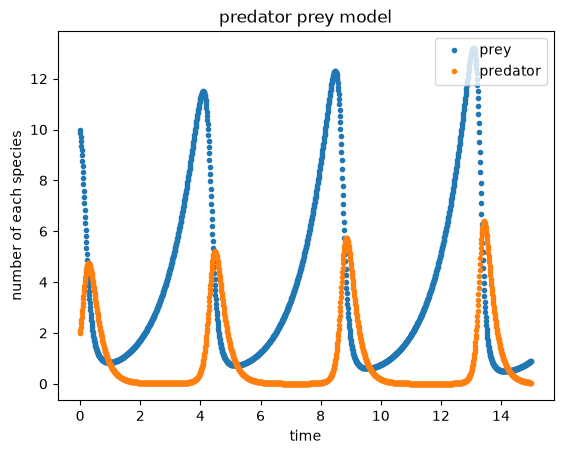

In [14]:
plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Let's think a bit about what this solution means, what is going on here?

Prey population increases up to a point then drops under predation pressure. Once predators eat enough of the prey population, predator population decreases to a point that prey population can climb up again.

What happens if we start with different initial conditions? Like more prey and less predators.

In [15]:
# initial conditions (initial populations):
x0 = 15. # initial prey amount
y0 = 0.001 # initial predator amount
t0 = 0.

In [16]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

In [17]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

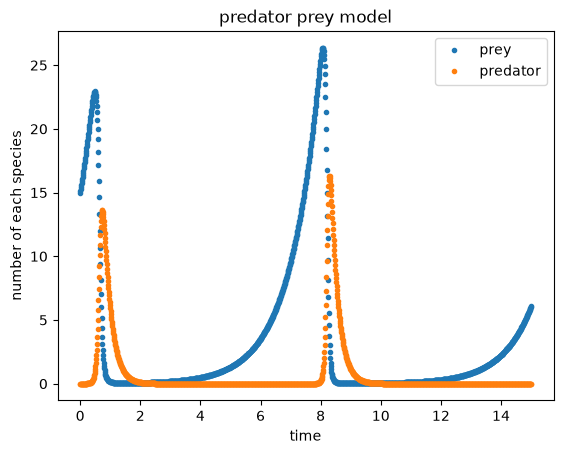

In [19]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What happened?

Prey have time to increase while predator populations increase. There's a slow down to how long it takes to go through the cycle.

What if we start with the same amount of prey and predators?

In [20]:
# set the parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [21]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [22]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

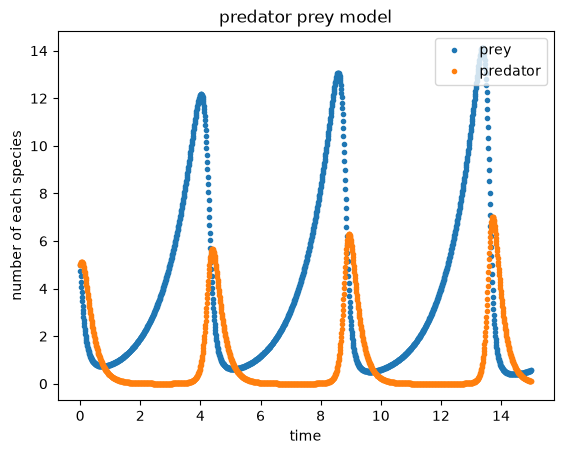

In [23]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

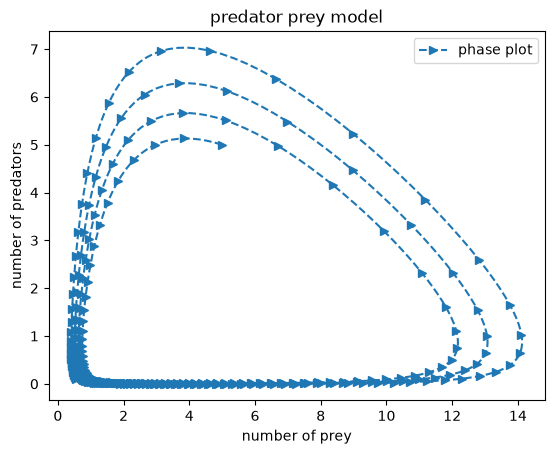

In [24]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

What happened?

Initally, prey and predator decline together. The following cycles see a peak of predators aligned with the decline after the peak in prey. 

Let's mess around with the model parameters. What if the prey grow faster?

In [25]:
# set the parameters
alpha = 10.
beta = 1.2
gamma = 4.
delta = 1.

In [26]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [27]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

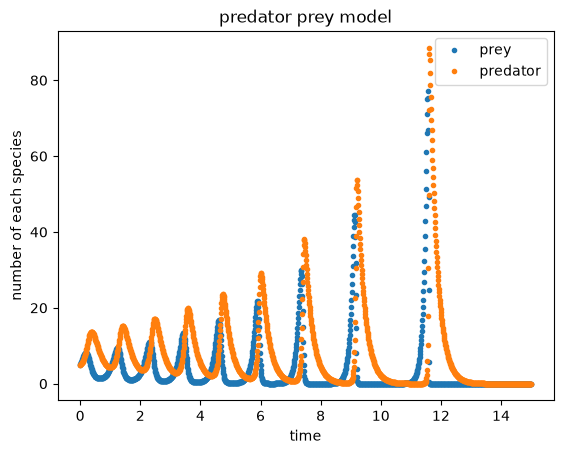

In [28]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What happened?

Predator population was able to exceed the prey and there is a shortening of time between cycles. There's also a gradual increase in overall population size over time.

### 12.2.3 System behavior

A better understanding of the system behavior can be obtained by a phase plot of the population of predators vs. the population of prey. It will tell us if the system sustains or collapses over time. For the choice of parameters $ \alpha, \beta, \gamma $ and $ \delta $ made above, we see that the maximum population of each species keeps increasing each cycle. You can read more about that in the Wikipedia link mentioned above.

Text(0.5, 1.0, 'predator prey model')

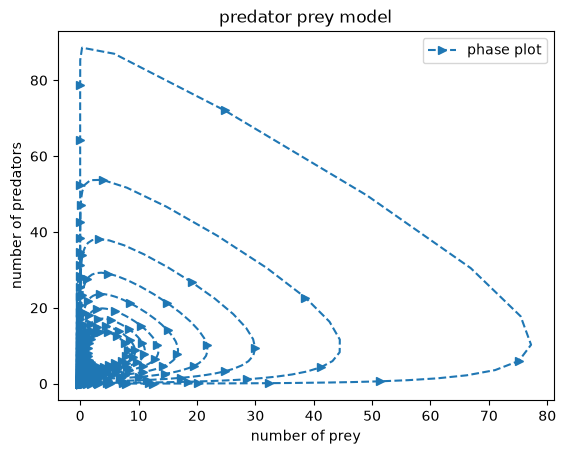

In [29]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

# Lab 12.2

#### E.1 How does timestep affect the solution?
Modify the timestep (or time increment) dt. How does this affect your solutions? Plot both the timeseries and the phase plots. Try making dt 10 times bigger (dt = 0.1) and 10 times smaller. Describe what happens to your results. What happens if you make dt 100 times smaller?

Making dt larger leads to longer time to complete the cycle and uneven peaks in populations and dramatic drops after the peaks. Decreasing dt leads to more even cyclical peaks for predator and prey and decreases in time between cycles.

Make dt 10 times bigger -- dt = 0.1

In [ ]:
# equation parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

# time-increment
T  = 15.0  # final time
dt = 0.1  # time-increment
N  = int(T/dt) + 1  # number of time-steps

# initial conditions:
x0 = 10. # prey amount
y0 = 2. # predator amount
t0 = 0.

In [ ]:
# array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# input initial conditions
u_euler[0] = np.array([x0, y0])

# for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

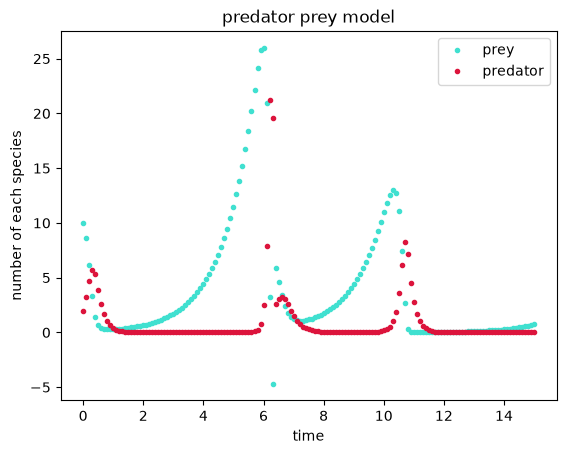

In [ ]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_euler, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

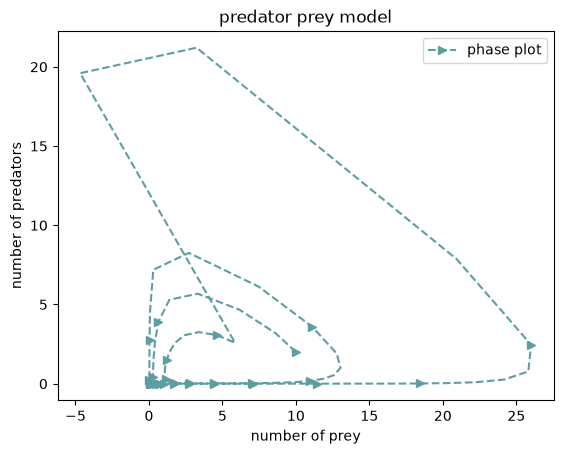

In [173]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

Make dt 10 times smaller -- dt = 0.001

In [174]:
# time-increment
T  = 15.0  # final time
dt = 0.001  # time-increment
N  = int(T/dt) + 1  # number of time-steps

In [175]:
# array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# input initial conditions
u_euler[0] = np.array([x0, y0])

# for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

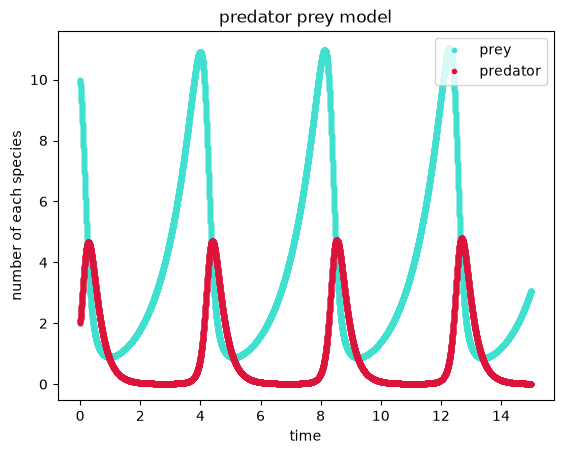

In [176]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_euler, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

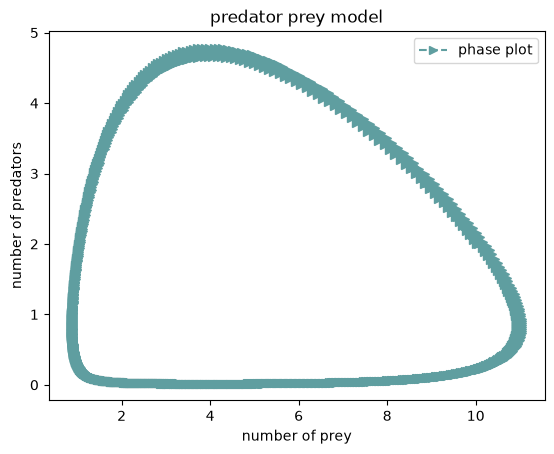

In [177]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

Make dt 100 times smaller -- dt = 0.0001

In [178]:
# time-increment
T  = 15.0  # final time
dt = 0.0001  # time-increment
N  = int(T/dt) + 1  # number of time-steps

In [179]:
# array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# input initial conditions
u_euler[0] = np.array([x0, y0])

# for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

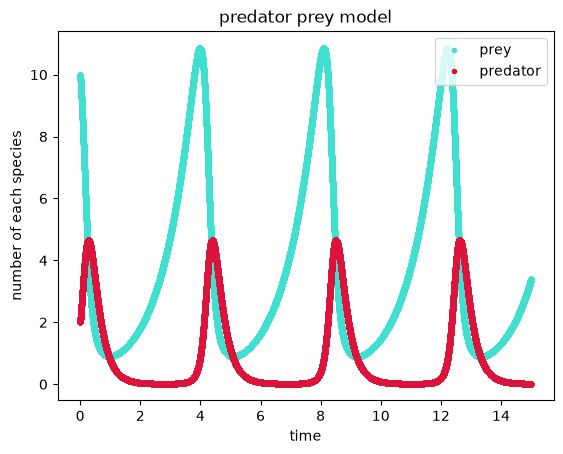

In [181]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_euler, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

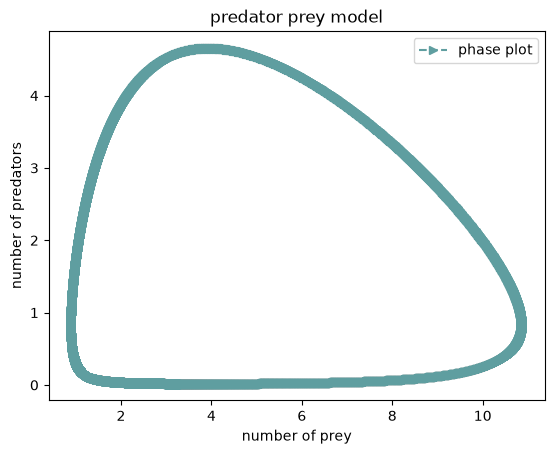

In [183]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

#### E.2 Adding the steady state

The steady state(s) of the system are found by setting the population equations to zero, that is the solution to when the population is not changing. This is also called a "fixed point" of the equations, since if the populations start there they stay there, i.e. are fixed.

Find the steady states of the system using algebra. Plot the fixed point (steady state population) of the system on both the timeseries and phase space plots. Describe where the fixed point is in the phase space plot and plot it. What happens if you start at the steady state? What happens if you start near the steady state?

The steady state values are 0.83 for the predator population and 4 for the prey population. When populations are set to start at these values, we see a static system with no change over time. When populations are set near these values, we see a steady, but flucuating, system over time. 

$\alpha x - \beta x y  = 0$

$\delta x y -\gamma y  = 0$

Equation parameters:  
$\alpha$ = 1   
$\beta$ = 1.2  
$\gamma$ = 4  
$\delta$ = 1  

$y = \alpha / \beta = 1/1.2 = 0.83$  
$x = \gamma / \delta = 4/1 = 4$

The steady state values are 0.83 for predator and 4 for prey. 

In [107]:
# equation parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

# time-increment
T  = 15.0  # final time
dt = 0.01  # time-increment
N  = int(T/dt) + 1  # number of time-steps

# initial conditions:
x0 = 10. # prey amount
y0 = 2. # predator amount
t0 = 0.

# steady state variables 
yst = alpha/beta
xst = gamma/delta

# array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# input initial conditions
u_euler[0] = np.array([x0, y0])

# for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

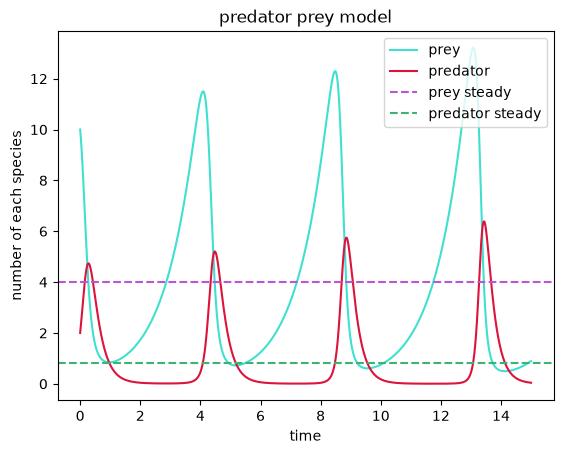

In [118]:
plt.plot(time, x_euler, label = 'prey ', color = 'turquoise')
plt.plot(time, y_euler, label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

# add steady state lines
plt.axhline(y = xst, linestyle = '--', label = 'prey steady', color ='mediumorchid')
plt.axhline(y = yst, linestyle = '--', label = 'predator steady', color = 'mediumseagreen')

plt.legend(loc='upper right')

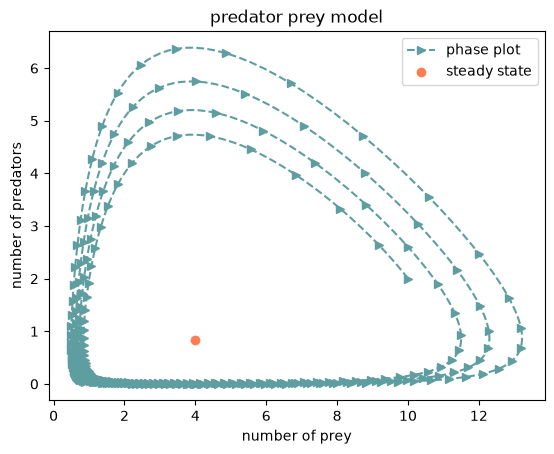

In [127]:
plt.plot(x_euler, y_euler, '-->', markevery=5, color = 'cadetblue', label = 'phase plot')

#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

# add steady state point
plt.scatter(xst, yst, marker = 'o', color = 'coral', label = 'steady state')

plt.legend(loc='upper right')

Initial populations set to steady state values

In [185]:
# equation parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

# time-increment
T  = 15.0  # final time
dt = 0.01  # time-increment
N  = int(T/dt) + 1  # number of time-steps

# initial conditions:
x0 = 4 # prey amount
y0 = 0.83 # predator amount
t0 = 0.

# array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# input initial conditions
u_euler[0] = np.array([x0, y0])

# for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

Text(0.5, 1.0, 'predator prey model')

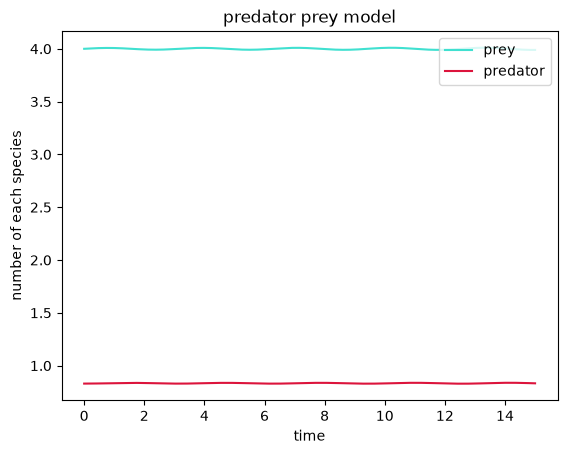

In [186]:
plt.plot(time, x_euler, label = 'prey ', color = 'turquoise')
plt.plot(time, y_euler, label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

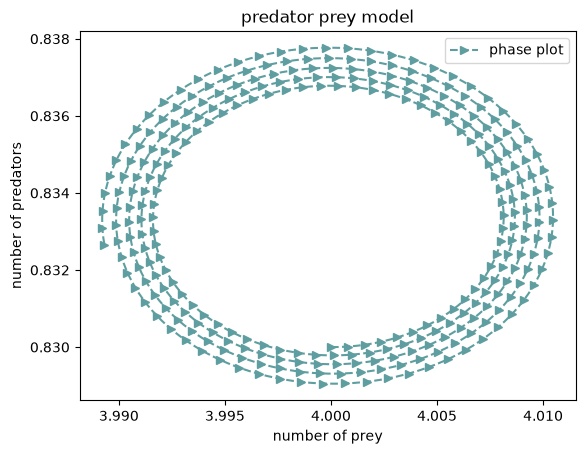

In [187]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

Set inital populations close to the steady state values

In [206]:
# initial conditions:
x0 = 4.5 # prey amount
y0 = 0.9 # predator amount
t0 = 0.

# array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# input initial conditions
u_euler[0] = np.array([x0, y0])

# for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

Text(0.5, 1.0, 'predator prey model')

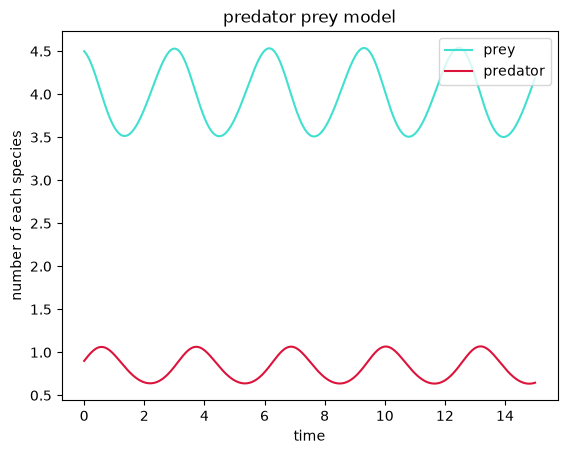

In [208]:
plt.plot(time, x_euler, label = 'prey ', color = 'turquoise')
plt.plot(time, y_euler, label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

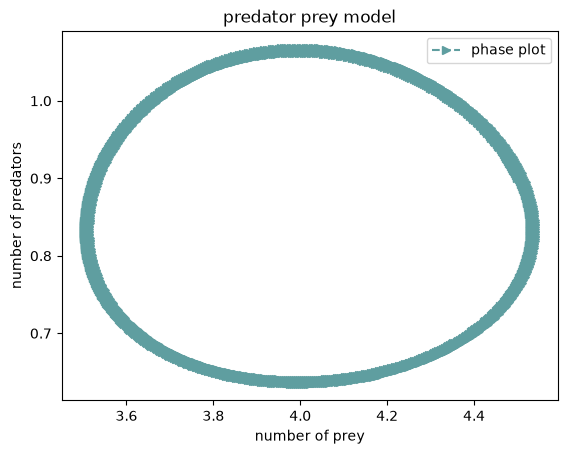

In [209]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

#### E.3 A better algorithm
Do Exercise 1 again with a fourth order time stepping method called "Runge-Kutta 4" whose algorithm is given below. How do your answers differ? How does the dt, the timestep, affect your answer using this "higher order" algorithm?

When compared to the Euler step method, the RK4 method seems to have lower sensitivity to changes in dt. The  pattern of peaks is maintained and the peak population size stays closer to the original values, especially with the increased dt value. The phase plot also maintains the general shape instead of developing that sharp dropoff point.  

In [50]:
def RK4(u,f,dt):
    # Runge Kutta 4th order method
    """Returns the solution at the next time-step using Runge Kutta fourth order (RK4) method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    #calculate slopes
    k1 = f(u)
    u1 = u + (dt/2.)*k1
    k2 = f(u1)
    u2 = u + (dt/2.)*k2
    k3 = f(u2)
    u3 = u + dt*k3
    k4 = f(u3)
    return u + (dt/6.)*(k1 + 2.*k2 + 2.*k3 + k4)

Original dt -- dt = 0.01

In [210]:
# equation parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

# time-increment
T  = 15.0  # final time
dt = 0.01  # time-increment
N  = int(T/dt) + 1  # number of time-steps

# initial conditions:
x0 = 10. # prey amount
y0 = 2. # predator amount
t0 = 0.

# array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

In [211]:
for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

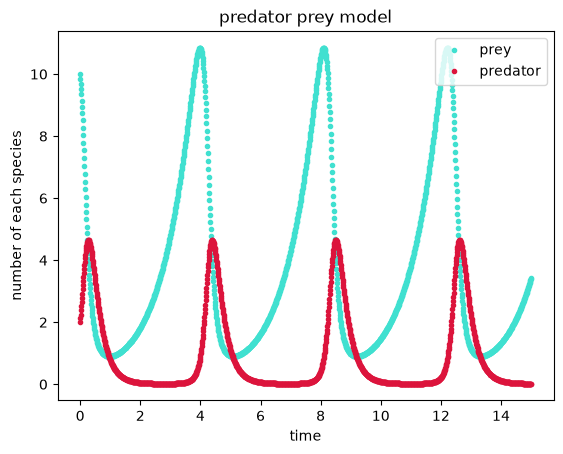

In [212]:
plt.plot(time, x_rk4, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_rk4, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")
plt.show()

Text(0.5, 1.0, 'predator prey model')

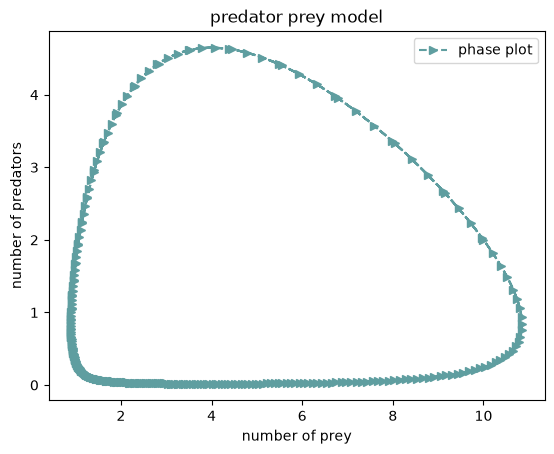

In [213]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

Make dt 10 times bigger -- dt = 0.1

In [214]:
T  = 15.0 
dt = 0.1  
N  = int(T/dt) + 1  

# initial conditions:
x0 = 10. # prey amount
y0 = 2. # predator amount
t0 = 0.

# array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

In [215]:
for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

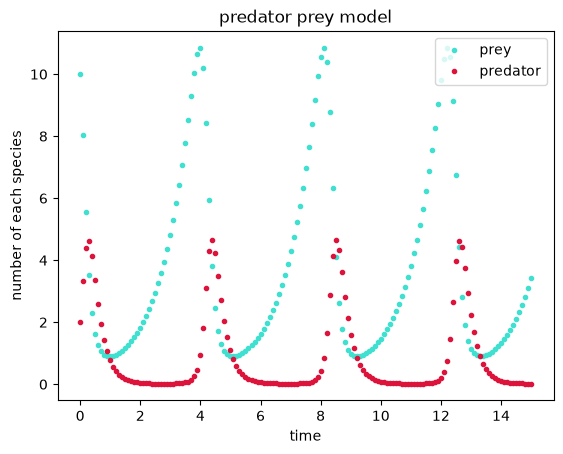

In [216]:
plt.plot(time, x_rk4, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_rk4, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")
plt.show()

Text(0.5, 1.0, 'predator prey model')

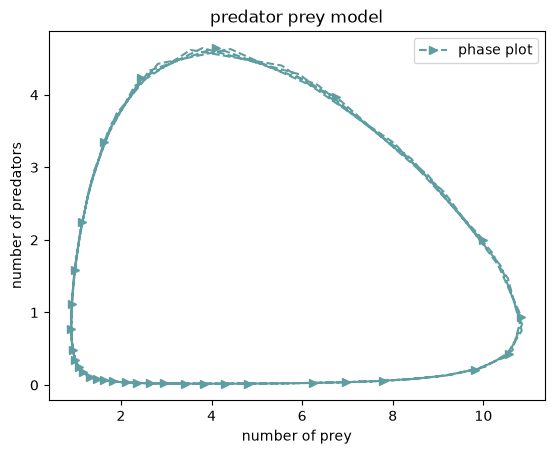

In [217]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

Make dt 10 times smaller -- dt = 0.001

In [218]:
T  = 15.0 
dt = 0.001  
N  = int(T/dt) + 1  

# initial conditions:
x0 = 10. # prey amount
y0 = 2. # predator amount
t0 = 0.

# array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

In [219]:
for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

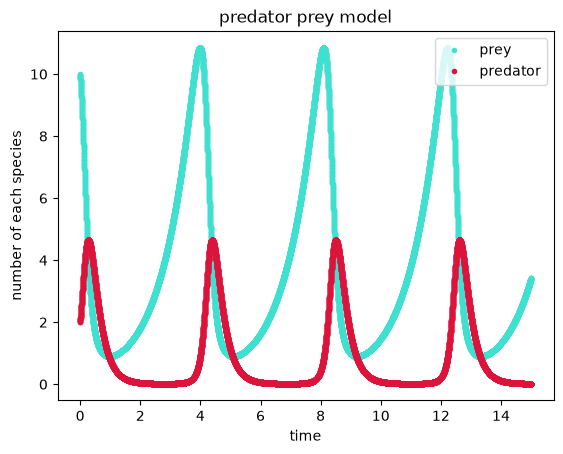

In [220]:
plt.plot(time, x_rk4, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_rk4, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")
plt.show()

Text(0.5, 1.0, 'predator prey model')

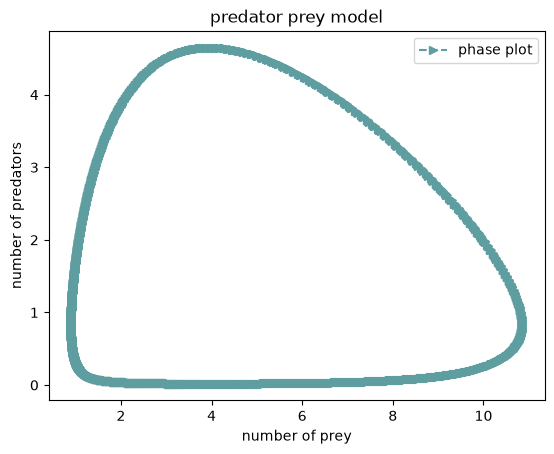

In [221]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

Make dt 100 times smaller -- dt = 0.0001

In [222]:
T  = 15.0 
dt = 0.001  
N  = int(T/dt) + 1  

# initial conditions:
x0 = 10. # prey amount
y0 = 2. # predator amount
t0 = 0.

# array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

In [223]:
for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

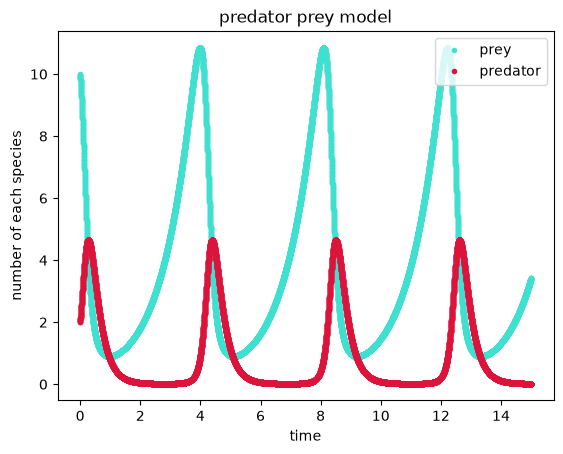

In [224]:
plt.plot(time, x_rk4, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_rk4, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")
plt.show()

Text(0.5, 1.0, 'predator prey model')

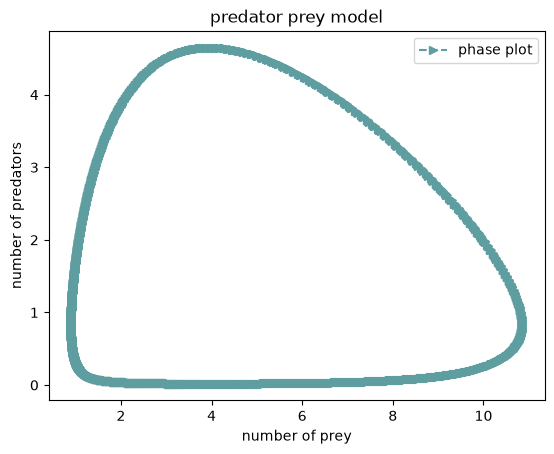

In [225]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

#### E.4 Exploring parameter space
Vary the interactions between species by changing $\alpha, \beta, \gamma, \delta$ and see what happens to the population evolution as well as phase plots. How does changing each parameter individually affect the system?

- Increasing the alpha parameter (prey growth rate) resulted in quicker cycles and higher peaks in both prey and predators. 
- Increasing beta (encounter rate/death of prey) resulted in very quick declines in prey populations once the predator population starts to climb.
- Increasing gamma (predator death rate) resulted in a steady oscillation from peak to a midpoint in prey populations. 
- Increasing delta (predator growth from consumption of prey) resulted in quick, large peaks in predator populations, followed by quick declines once prey has been depleted.

Increase alpha - prey growth rate

In [226]:
# equation parameters
alpha = 5.
beta = 1.2
gamma = 4.
delta = 1.

# time-increment
T  = 15.0  # final time
dt = 0.01  # time-increment
N  = int(T/dt) + 1  # number of time-steps

# initial conditions:
x0 = 10. # prey amount
y0 = 2. # predator amount
t0 = 0.

# array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

In [227]:
for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

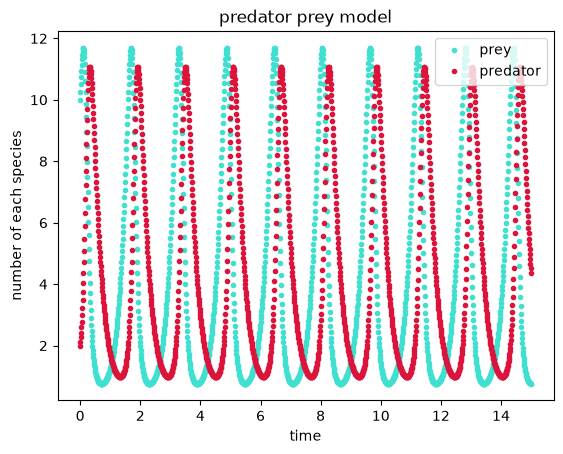

In [228]:
plt.plot(time, x_rk4, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_rk4, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")
plt.show()

Text(0.5, 1.0, 'predator prey model')

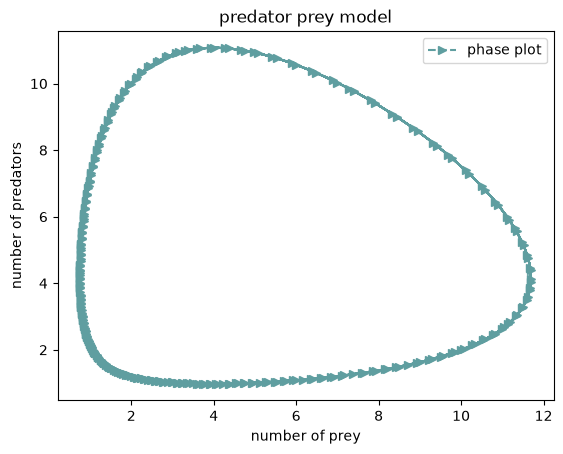

In [229]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

Increase beta - predator prey encounter rate/prey population decline rate

In [230]:
# equation parameters
alpha = 1.
beta = 5.5
gamma = 4.
delta = 1.

# time-increment
T  = 15.0  # final time
dt = 0.01  # time-increment
N  = int(T/dt) + 1  # number of time-steps

# initial conditions:
x0 = 10. # prey amount
y0 = 2. # predator amount
t0 = 0.

# array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

In [231]:
for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

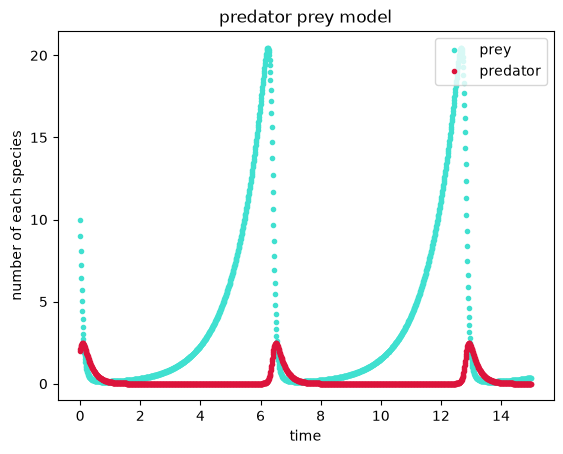

In [232]:
plt.plot(time, x_rk4, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_rk4, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")
plt.show()

Text(0.5, 1.0, 'predator prey model')

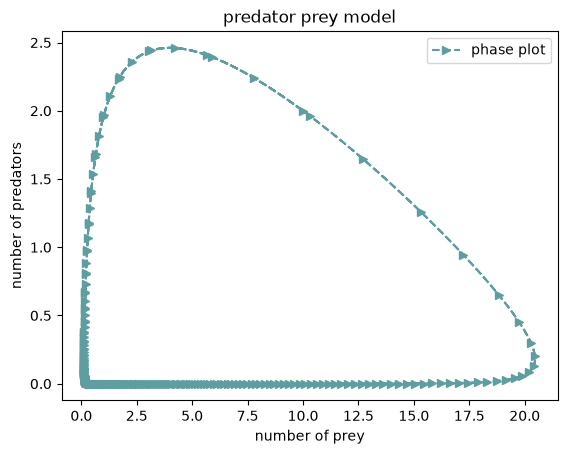

In [233]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

Increase gamma - predator death rate

In [236]:
# equation parameters
alpha = 1.
beta = 1.2
gamma = 9.
delta = 1.

# time-increment
T  = 15.0  # final time
dt = 0.01  # time-increment
N  = int(T/dt) + 1  # number of time-steps

# initial conditions:
x0 = 10. # prey amount
y0 = 2. # predator amount
t0 = 0.

# array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

In [237]:
for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

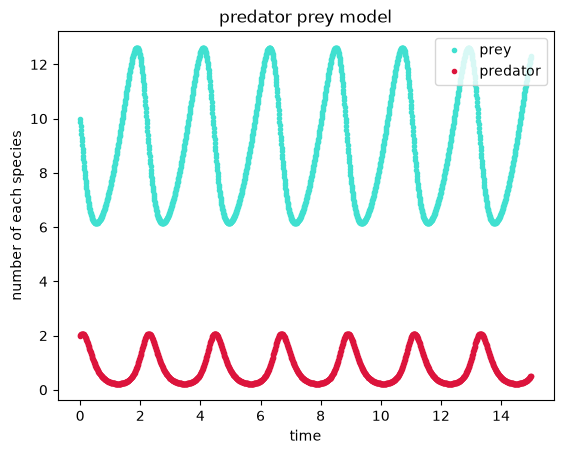

In [238]:
plt.plot(time, x_rk4, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_rk4, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")
plt.show()

Text(0.5, 1.0, 'predator prey model')

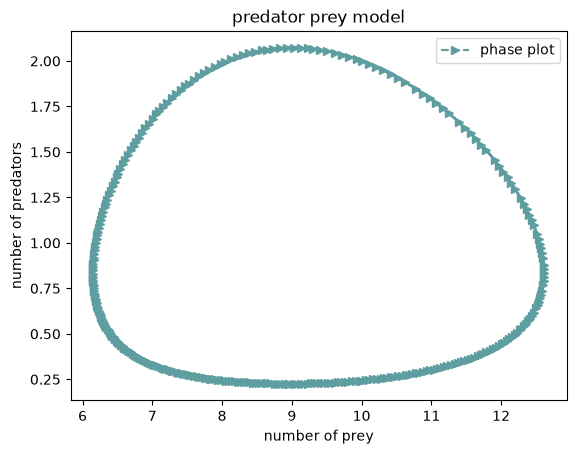

In [239]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

Increase delta - estimate of predator growth based on prey encounter

In [240]:
# equation parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 5.

# time-increment
T  = 15.0  # final time
dt = 0.01  # time-increment
N  = int(T/dt) + 1  # number of time-steps

# initial conditions:
x0 = 10. # prey amount
y0 = 2. # predator amount
t0 = 0.

# array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

In [241]:
for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

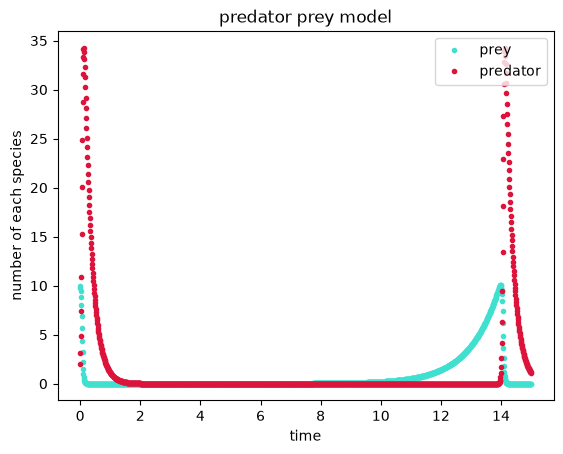

In [242]:
plt.plot(time, x_rk4, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_rk4, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")
plt.show()

Text(0.5, 1.0, 'predator prey model')

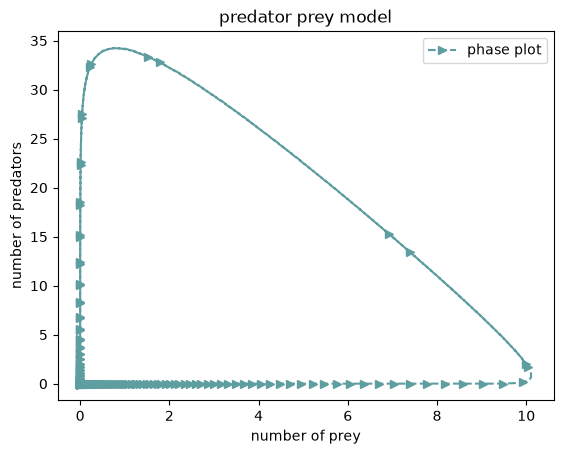

In [243]:
plt.plot(x_rk4, y_rk4, '-->', markevery=5, label = 'phase plot', color = 'cadetblue')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

#### E.5 (Advanced, required for grad students)
Modify the differential equations to include other types of interactions. See advanced predator prey example link at the top for ideas. You might add in a self-eating (i.e. $-ay^2$) term into the predator equation. Or do the zombie apocalypse example linked above.

Addition of carrying capacity (K) to the prey population. Sets upper limit of sustainable population size for prey. Instead of $\alpha x$, use $\alpha x(1 - x/K)$

In [379]:
# equation parameters - adjusted from original example
# added K for carrying capacity
alpha = 1.5
beta = 2.8
gamma = 3.
delta = 2.5
K = 10

In [372]:
# editted equation function
def f(u):
    """Returns the rate of change of species
    
    Parameters
    ----------
    u : array of float
        array containing the solution at time n.
        
    Returns
    -------
    dudt : array of float
        array containing the RHS given u.
    """
    x = u[0]
    y = u[1]
    return np.array([x*(alpha*(1-x/K) - beta*y), -y*(gamma - delta*x)])

In [246]:
def RK4(u,f,dt):
    # Runge Kutta 4th order method
    """Returns the solution at the next time-step using Runge Kutta fourth order (RK4) method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    #calculate slopes
    k1 = f(u)
    u1 = u + (dt/2.)*k1
    k2 = f(u1)
    u2 = u + (dt/2.)*k2
    k3 = f(u2)
    u3 = u + dt*k3
    k4 = f(u3)
    return u + (dt/6.)*(k1 + 2.*k2 + 2.*k3 + k4)

In [380]:
# time-increment
T  = 15.0  # final time
dt = 0.01  # time-increment
N  = int(T/dt) + 1  # number of time-steps

# initial conditions:
x0 = 8. # prey amount - adjusted
y0 = 2. # predator amount
t0 = 0.

# array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])

In [381]:
for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

Text(0.5, 1.0, 'predator prey model')

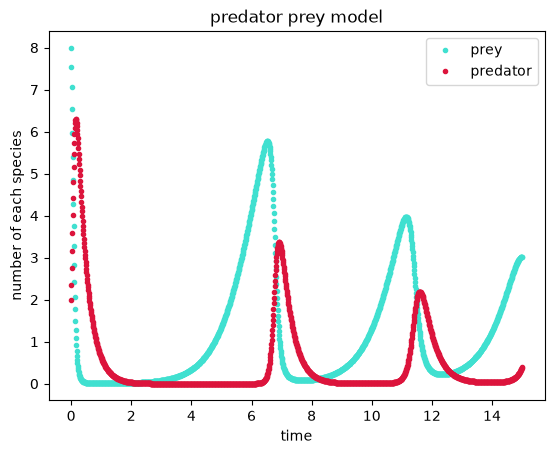

In [382]:
plt.plot(time, x_rk4, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_rk4, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Addition of variable hunger in predators. Replaces the $\beta x$ and $\delta x$ terms in the equations with $\frac{\beta x}{1 + (h \beta x)}$.

In [383]:
# equation parameters - adjusted predator growth, encounter, predator death
alpha = 1.5
beta = 2.8
gamma = 3.
delta = 2.5
K = 10.
h = 0.75

In [384]:
# editted equation function
def f(u):
    """Returns the rate of change of species
    
    Parameters
    ----------
    u : array of float
        array containing the solution at time n.
        
    Returns
    -------
    dudt : array of float
        array containing the RHS given u.
    """
    x = u[0]
    y = u[1]
    return np.array([x*alpha*(1-x/K) - ((beta*x)/(1+(h*beta*x))), -y*(gamma - ((delta*beta*x)/(1+(h*beta*x))))])

In [385]:
# time-increment
T  = 15.0  # final time
dt = 0.01  # time-increment
N  = int(T/dt) + 1  # number of time-steps

# initial conditions:
x0 = 8. # prey amount
y0 = 2. # predator amount
t0 = 0.

# array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# input initial conditions
u_rk4[0] = np.array([x0, y0])
for n in range(N - 1):
    u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

time = np.linspace(0.0, T, N)
x_rk4 = u_rk4[:, 0]
y_rk4 = u_rk4[:, 1]

Text(0.5, 1.0, 'predator prey model')

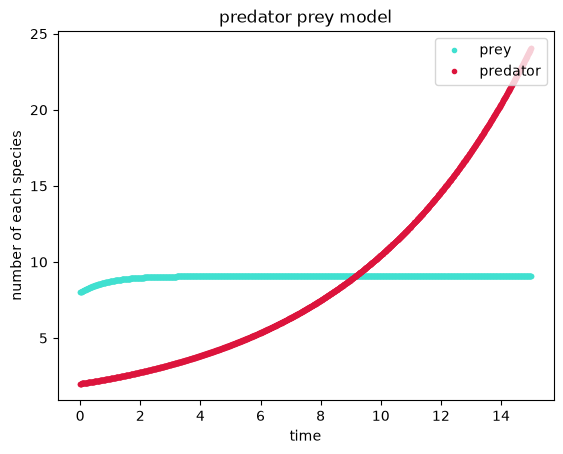

In [386]:
plt.plot(time, x_rk4, '.', label = 'prey ', color = 'turquoise')
plt.plot(time, y_rk4, '.', label = 'predator', color = 'crimson')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")